## Análsis del Raster de Preciiptación


In [20]:
import pandas as pd 
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent
from rasterio.windows import from_bounds
import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import Transformer
import shapely
from rasterio.mask import mask
from shapely.geometry import mapping
from shapely.geometry import box
from rasterio.transform import xy

In [4]:


parcelas_gdf = gpd.read_file('../../DataSet/DATASET_RETO_AGRO_2026/Parcelas_Reto_AGC_CONJUNTO_70_30/Parcelas_Reto_AGC_CONJUNTO.shp')

parcelas_gdf.head()

,Cultivo,ID_POLIGON,área_ha,Municipio,Estado,CONJUNTO,geometry
0,Cebada,AGC_196,8.57,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.57739 19.65802 0, -98.57751 19..."
1,Cebada,AGC_044,0.68,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58655 19.62943 0, -98.5862 19...."
2,Cebada,AGC_020,8.34,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58494 19.6278 0, -98.58656 19...."
3,CEBADA,AGC_174,6.89,Cuautepec de Hinojosa,Hidalgo,PREDICCION,"POLYGON Z ((-98.30604 19.9 0, -98.30486 19.899..."
4,CEBADA,AGC_083,2.87,Cuautepec de Hinojosa,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.29383 19.8882 0, -98.29378 19...."


In [5]:
print(f'Shape: {parcelas_gdf.shape}')
print(f'CRS: {parcelas_gdf.crs}')
print(f'Columns: {parcelas_gdf.columns}')

Shape: (197, 7)
CRS: EPSG:4326
Columns: Index(['Cultivo', 'ID_POLIGON', 'área_ha', 'Municipio', 'Estado', 'CONJUNTO',
       'geometry'],
      dtype='str')


4326 significa que la geometría esta expresado en latitud y longitud.

In [6]:
#Tipo de geometría
print(f'Tipo geometría: {parcelas_gdf.geometry.geom_type.value_counts()}')
print(f'Info: {parcelas_gdf.info()}')

Tipo geometría: Polygon    197
Name: count, dtype: int64
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Cultivo     197 non-null    str     
 1   ID_POLIGON  197 non-null    str     
 2   área_ha     197 non-null    float64 
 3   Municipio   197 non-null    str     
 4   Estado      197 non-null    str     
 5   CONJUNTO    197 non-null    str     
 6   geometry    197 non-null    geometry
dtypes: float64(1), geometry(1), str(5)
memory usage: 10.9 KB
Info: None


In [7]:
precipitation_path = '../../DataSet/DATASET_RETO_AGRO_2026/Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/Precipitacion_mensual/2025/PREC_2025_01.tif'

with rasterio.open(precipitation_path) as src:
    print('CRS: ', src.crs)
    print('Dimensiones: ', src.width, src.height)
    print('Número de bandas: ', src.count)
    print('Resolución: ', src.res)
    print('Bounds: ', src.bounds)
    print('No Data: ', src.nodata)
    print('tipo de dato: ', src.dtypes)

CRS:  EPSG:4326
Dimensiones:  65 72
Número de bandas:  1
Resolución:  (0.05000000074505806, 0.05000000074505806)
Bounds:  BoundingBox(left=-99.94999880716205, bottom=17.79999952018261, right=-96.69999875873327, top=21.39999957382679)
No Data:  -9999.0
tipo de dato:  ('float32',)


CRS: EPSG:4326
Resolución: (0.05000000074505806, 0.05000000074505806)
Shape: 72 65
NoData: -9999.0
Bounds: BoundingBox(left=-99.94999880716205, bottom=17.79999952018261, right=-96.69999875873327, top=21.39999957382679)
Valor mínimo:  1.4133751
Valor máximo:  93.62358
Promedio:  21.839315


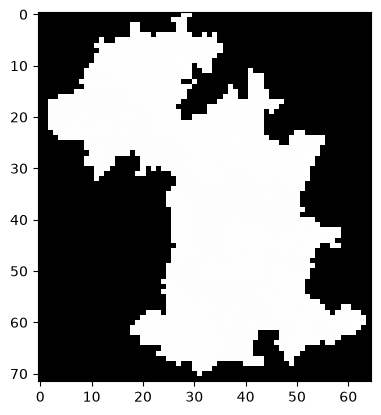

In [10]:
with rasterio.open(precipitation_path) as src:
    precipitation = src.read(1)


print("CRS:", src.crs)
print("Resolución:", src.res)
print("Shape:", src.height, src.width)
print("NoData:", src.nodata)
print("Bounds:", src.bounds)
print('Valor mínimo: ', np.nanmin(np.where(precipitation == -9999, np.nan, precipitation)))
print('Valor máximo: ', np.nanmax(np.where(precipitation == -9999, np.nan, precipitation)))
print('Promedio: ', np.nanmean(np.where(precipitation == -9999, np.nan, precipitation))) 

    
plt.imshow(precipitation, cmap='gray')

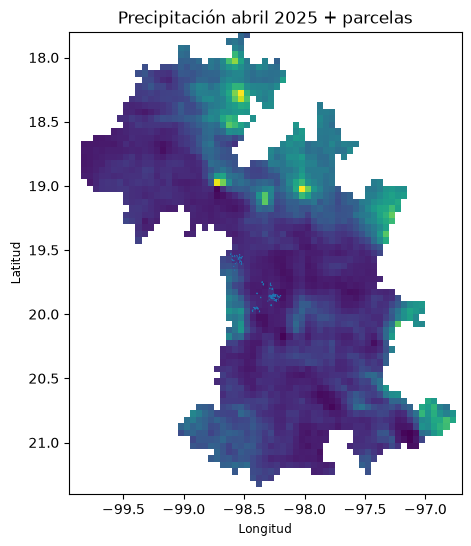

In [11]:
with rasterio.open(precipitation_path) as src:
    src.read(1)
    extent = [src.bounds.left, src.bounds.right, src.bounds.top, src.bounds.bottom]
    
fig, ax = plt.subplots(figsize=(8, 6))

precipitation_map = precipitation.astype(float)
precipitation_map[precipitation_map == -9999] = np.nan

ax.imshow(precipitation_map, extent=extent, origin='upper')
parcelas_gdf.boundary.plot(ax=ax, linewidth =0.5)

ax.set_title("Precipitación abril 2025 + parcelas")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

plt.show()

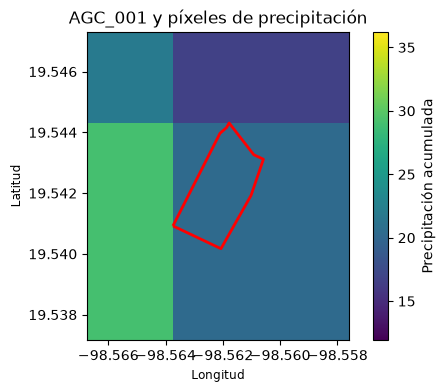

In [13]:
parcela_001 = parcelas_gdf[
    parcelas_gdf["ID_POLIGON"] == "AGC_001"
].copy()

with rasterio.open(precipitation_path) as src:

    # Parcela en CRS del raster
    parcela_001_4326 = parcela_001.to_crs(src.crs)

    xmin, ymin, xmax, ymax = parcela_001_4326.total_bounds

    # Margen de 0.1 grados
    margen = 0.1

    window = from_bounds(
        xmin - margen,
        ymin - margen,
        xmax + margen,
        ymax + margen,
        src.transform
    )

    precipitacion = src.read(
        1,
        window=window
    )

    transform_window = src.window_transform(window)

    precipitacion = precipitacion.astype(float)
    precipitacion[
        precipitacion == src.nodata
    ] = np.nan

    extent = plotting_extent(
        precipitacion,
        transform_window
    )

fig, ax = plt.subplots(figsize=(6, 4))

im = ax.imshow(
    precipitacion,
    extent=extent,
    origin="upper"
)

parcela_001_4326.boundary.plot(
    ax=ax,
    linewidth=2,
    color="red"
)

ax.set_title(
    "AGC_001 y píxeles de precipitación"
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

plt.colorbar(
    im,
    ax=ax,
    label="Precipitación acumulada"
)

# Límites de la parcela
xmin, ymin, xmax, ymax = parcela_001_4326.total_bounds

# Ampliar la visualización alrededor de la parcela
margen = 0.003

ax.set_xlim(xmin - margen, xmax + margen)
ax.set_ylim(ymin - margen, ymax + margen)

plt.show()

In [21]:
def get_precipitation(raster_path, parcela):
    with rasterio.open(raster_path) as src:
        parcela_geom = parcela.to_crs(src.crs)
        parcela_geom = parcela_geom.geometry.iloc[0]
        
        #Recortamos los pixeles del raster que intersacatn con la parcela
        values, transform = mask(src, [mapping(parcela_geom)], crop=True, filled=False, all_touched=True)
        
        #Objeto para transformar de coordendas a metros
        transfomer = Transformer.from_crs(src.crs, 'EPSG:6372', always_xy=True)
        
        #Parcela en metros
        parcela_m = parcela.to_crs('EPSG:6372')
        geometry_m = parcela_m.geometry.iloc[0]
        
        area_total = geometry_m.area
        area_valida = 0
        suma_ponderada = 0
        pixeles_validos = 0
        
        for i in range(values.shape[1]):
            for j in range(values.shape[2]):
                
                #Ignoramos los pixeles que no tienen datos
                if  np.ma.getmaskarray(values)[0, i, j]:
                    continue
                
                valor = float(values[0, i, j])

                if not np.isfinite(valor):
                    continue

                # Límites del píxel en el CRS del raster
                x1, y1 = xy(transform, i, j, offset="ul")

                x2, y2 = xy(transform, i, j, offset="lr")

                pixel_geo = box(x1, y2, x2, y1)

                # Transformar el píxel a coordenadas métricas
                pixel_m = shapely.ops.transform(transfomer.transform,pixel_geo)

                # Intersección real con la parcela
                interseccion = pixel_m.intersection(geometry_m)
                area_interseccion = interseccion.area

                if area_interseccion <= 0:
                    continue

                area_valida += area_interseccion
                suma_ponderada += valor * area_interseccion
                pixeles_validos += 1

        media_ponderada = (
            suma_ponderada / area_valida
            if area_valida > 0
            else np.nan
        )

        return {
            "area_total_m2": area_total,
            "area_valida_m2": area_valida,
            "cobertura_pct": 100 * area_valida / area_total,
            "precipitacion_media": media_ponderada,
            "pixeles_validos": pixeles_validos
        }

In [22]:
precipitation_results = []

for _, parcela in parcelas_gdf.iterrows():
    parcela_gdf = gpd.GeoDataFrame([parcela], geometry="geometry",crs=parcelas_gdf.crs)
    
    result = get_precipitation(precipitation_path, parcela_gdf)
    result["ID_POLIGON"] = parcela["ID_POLIGON"]

    precipitation_results.append(result)
    

In [23]:
precipitation_df = pd.DataFrame(precipitation_results)

precipitation_df = precipitation_df[
    [
        "ID_POLIGON",
        "precipitacion_media",
        "cobertura_pct",
        "pixeles_validos",
        "area_total_m2",
        "area_valida_m2"
    ]
]

display(precipitation_df.head())

,ID_POLIGON,precipitacion_media,cobertura_pct,pixeles_validos,area_total_m2,area_valida_m2
0,AGC_196,11.715059,100.0,1,85130.668788,85130.668788
1,AGC_044,14.340641,100.0,1,6760.402971,6760.402971
2,AGC_020,14.340641,100.0,1,82856.226598,82856.226598
3,AGC_174,18.443747,100.0,1,68423.862739,68423.862739
4,AGC_083,17.910559,100.0,1,28466.739798,28466.739798


In [24]:
print("Dimensiones:", precipitation_df.shape)
print("IDs únicos:", precipitation_df["ID_POLIGON"].nunique())
print("IDs duplicados:", precipitation_df["ID_POLIGON"].duplicated().sum())


Dimensiones: (197, 6)
IDs únicos: 197
IDs duplicados: 0


In [25]:
print(precipitation_df["precipitacion_media"].describe())

count    197.000000
mean      17.396512
std        3.672336
min       11.715059
25%       14.107316
50%       17.910559
75%       18.093159
max       32.748020
Name: precipitacion_media, dtype: float64


la media es de 17.40 mm, pero el máximo alcanza 32.75 mm. Esto indica variación espacial entre las parcelas

In [26]:
print(precipitation_df["cobertura_pct"].describe())

print(
    precipitation_df[precipitation_df["cobertura_pct"] < 99.999][["ID_POLIGON", "cobertura_pct", "precipitacion_media"]])

print(
    "Parcelas sin precipitación:",precipitation_df["precipitacion_media"].isna().sum())

count    1.970000e+02
mean     1.000000e+02
std      8.816397e-12
min      1.000000e+02
25%      1.000000e+02
50%      1.000000e+02
75%      1.000000e+02
max      1.000000e+02
Name: cobertura_pct, dtype: float64
Empty DataFrame
Columns: [ID_POLIGON, cobertura_pct, precipitacion_media]
Index: []
Parcelas sin precipitación: 0
